# ConvNeXt – OASIS Dementia Classification
**Model:** ConvNeXt (ImageNet-1K)  
**Split:** patient-level 80/20  

## 0 · Runtime & GPU check

In [1]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 15.6 GB


## 1 · Imports

In [2]:
# !pip install kagglehub -q
import os, re, numpy as np, matplotlib.pyplot as plt, matplotlib.cm as cm
import torch, torch.nn as nn, torch.nn.functional as F
import kagglehub, pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from sklearn.metrics import f1_score, classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.benchmark        = True
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2 · Config

In [3]:
class_names_folder = [
    "Mild Dementia",
    "Moderate Dementia",
    "Non Demented",
    "Very mild Dementia",
]
class_labels = ["Mild", "Moderate", "Non Dem", "Very Mild"]
n_classes    = 4
img_size     = (224, 224)
batch_size   = 32
lr           = 1e-4   # 2e-5
weight_decay = 0.05   # 1e-2
epochs       = 1
dropout      = 0.35
patience     = 5
log_steps    = 50
seed         = 274
torch.manual_seed(seed)

## 3 · Dataset download & patient-level split
OASIS filenames encode the subject ID, e.g. `OAS1_0001_MR1_mpr-1_100.jpg`. We extract the subject prefix (`OAS1_0001`) and split on unique subjects, so no patient's slices can appear in both train and val — avoiding data leakage.

In [4]:
path     = kagglehub.dataset_download("ninadaithal/imagesoasis")
data_dir = Path(path) / "Data"
print("Folders:", [f.name for f in sorted(data_dir.iterdir())])

Using Colab cache for faster access to the 'imagesoasis' dataset.
Folders: ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']


In [5]:
def extract_subject(filename: str) -> str:
    """
    Extracts subject ID from OASIS filenames.
    Handles two common patterns:
      OAS1_0001_MR1_mpr-1_100.jpg  →  OAS1_0001
      mci_OAS2_0042_MR2_100.jpg    →  OAS2_0042
    Falls back to the full stem if no match found.
    """
    m = re.search(r'(OAS[12]_\d+)', filename)
    return m.group(1) if m else Path(filename).stem

rows = []
for label_idx, folder_name in enumerate(class_names_folder):
    folder = data_dir / folder_name
    for img_path in sorted(folder.glob("*.jpg")):
        rows.append({
            "path":    str(img_path),
            "label":   label_idx,
            "subject": extract_subject(img_path.name),
        })
df = pd.DataFrame(rows)
print(f"Total images : {len(df)}")
print(f"Unique subjects: {df.subject.nunique()}")
print("\nPer-class counts:")
print(df.label.value_counts().sort_index().rename(index=dict(enumerate(class_names_folder))))

Total images : 86437
Unique subjects: 347

Per-class counts:
label
Mild Dementia          5002
Moderate Dementia       488
Non Demented          67222
Very mild Dementia    13725
Name: count, dtype: int64


In [6]:
subjects = df.subject.unique()
rng      = np.random.default_rng(seed)
rng.shuffle(subjects)
split_idx    = int(len(subjects) * 0.8)
train_subj   = set(subjects[:split_idx])
val_subj     = set(subjects[split_idx:])

train_df = df[df.subject.isin(train_subj)].reset_index(drop=True)
val_df   = df[df.subject.isin(val_subj)].reset_index(drop=True)

print(f"Train : {len(train_df)} images | {len(train_subj)} subjects")
print(f"Val   : {len(val_df)} images | {len(val_subj)} subjects")

assert not train_subj & val_subj, "Subject overlap detected!"
print("\nNo subject overlap confirmed.")

Train : 69723 images | 277 subjects
Val   : 16714 images | 70 subjects

No subject overlap confirmed.


## 4 · Transforms

In [7]:
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(img_size),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## 5 · Dataset

In [8]:
class OASIS(Dataset):
    def __init__(self, df, transform):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row.path).convert("L")
        return {
            "pixel_values": self.transform(img),
            "labels":        torch.tensor(row.label, dtype=torch.long),
            "path":          row.path,
        }

train_ds = OASIS(train_df, train_transform)
val_ds = OASIS(val_df, val_transform)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
print(f"Train: {len(train_ds)} images  |  Val: {len(val_ds)} images")

Train: 69723 images  |  Val: 16714 images


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## 6 · Sample images

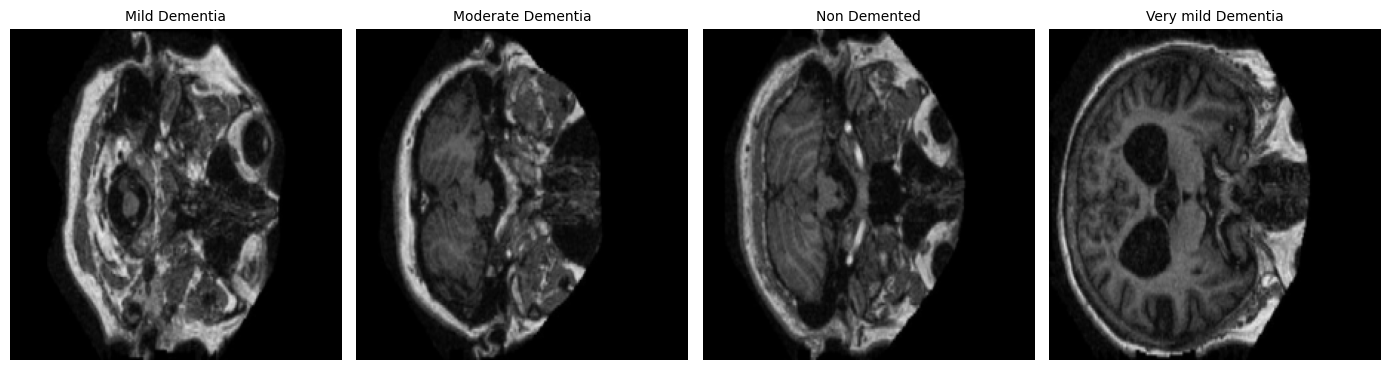

In [9]:
not_flat_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
not_flat_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def denormalise(tensor):
    return (tensor.cpu() * not_flat_std + not_flat_mean).permute(1, 2, 0).numpy().clip(0, 1)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for cls_idx in range(n_classes):
    row = val_df[val_df.label == cls_idx].iloc[0]
    img = Image.open(row.path).convert("L")
    tensor = val_transform(img)
    ax = axes[cls_idx]
    ax.imshow(denormalise(tensor), cmap="gray")
    ax.set_title(class_names_folder[cls_idx], fontsize=10, pad=6)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7 · Model

In [10]:
class ConvNeXtOASIS(nn.Module):
    def __init__(self, num_classes=n_classes, dropout=dropout):
        super().__init__()
        backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        self.features = backbone.features
        self.avgpool = backbone.avgpool
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(768),
            nn.Dropout(dropout),
            nn.Linear(768, num_classes),
        )
    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.classifier(x)
        return x

model = ConvNeXtOASIS().to(device)
print("Model initialized onto:", device)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 128MB/s]


Model initialized onto: cuda


## 8 · Loss, optimiser, scaler

In [11]:
raw_weights = compute_class_weight("balanced", classes=np.arange(n_classes), y=train_df.label.values)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(raw_weights, dtype=torch.float, device=device))
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

/tmp/ipykernel_1602/86465036.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


## 9 · Training

In [12]:
import time

log_steps = 50
EVAL_STEPS = 50

def eval_epoch(model, loader):
    model.eval()
    total_loss, all_labels, all_preds = 0.0, [], []

    with torch.no_grad():
        for batch in loader:
            imgs = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            with torch.autocast(
                device_type="cuda" if "cuda" in device else "cpu",
                enabled=torch.cuda.is_available()
            ):
                logits = model(imgs)
                loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(logits.argmax(-1).cpu().numpy())

    n = len(all_labels)

    return {
        "loss": total_loss / n,
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_weighted": f1_score(all_labels, all_preds, average="weighted", zero_division=0),
    }, all_labels, all_preds


def train_epoch(model, loader, epoch):
    model.train()

    running_loss, running_correct, running_n = 0.0, 0, 0

    for step, batch in enumerate(loader, 1):

        imgs = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda" if "cuda" in device else "cpu",
            enabled=torch.cuda.is_available()
        ):
            logits = model(imgs)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        preds = logits.argmax(-1)
        bs = labels.size(0)

        running_loss += loss.item() * bs
        running_correct += (preds == labels).sum().item()
        running_n += bs

    return running_loss, running_correct, running_n

In [13]:
best_f1, best_state = 0.0, None
global_step = 0

last_val = {
    "loss": float("nan"),
    "acc": float("nan"),
    "f1": float("nan")
}

print("step\ttrain_loss\ttrain_acc\tval_loss\tval_acc\tval_f1")

for epoch in range(1, epochs + 1):

    print(f"\nEpoch {epoch}/{epochs}")

    running_loss, running_correct, running_n = 0.0, 0, 0

    for step, batch in enumerate(train_loader, 1):

        global_step += 1

        imgs = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda" if "cuda" in device else "cpu",
            enabled=torch.cuda.is_available()
        ):
            logits = model(imgs)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        preds = logits.argmax(-1)
        bs = labels.size(0)

        running_loss += loss.item() * bs
        running_correct += (preds == labels).sum().item()
        running_n += bs

        if global_step % EVAL_STEPS == 0:

            val_met, val_labels, val_preds = eval_epoch(model, val_loader)

            last_val["loss"] = val_met["loss"]
            last_val["acc"]  = val_met["accuracy"]
            last_val["f1"]   = val_met["f1_macro"]

            if last_val["f1"] > best_f1:
                best_f1 = last_val["f1"]

                best_state = {
                    k: v.cpu().clone()
                    for k, v in model.state_dict().items()
                }

                torch.save(best_state, "best_convnext_tiny_oasis.pt")

        if global_step % log_steps == 0:

            print(
                f"{global_step}\t"
                f"{running_loss/running_n:.4f}\t"
                f"{running_correct/running_n:.4f}\t"
                f"{last_val['loss']:.4f}\t"
                f"{last_val['acc']:.4f}\t"
                f"{last_val['f1']:.4f}"
            )

            running_loss = 0.0
            running_correct = 0
            running_n = 0

step	train_loss	train_acc	val_loss	val_acc	val_f1

Epoch 1/1


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


50	1.4601	0.5737	1.0862	0.4579	0.2929
100	0.9089	0.7013	0.9695	0.5810	0.3501
150	0.9657	0.7063	0.9207	0.5501	0.3157
200	0.7284	0.7350	1.2610	0.4368	0.3071
250	0.7200	0.7419	0.9087	0.6171	0.3839
300	0.7064	0.7362	0.8568	0.6203	0.3364
350	0.8311	0.6750	0.9306	0.6195	0.3665
400	0.6837	0.7469	0.8887	0.6266	0.3445
450	0.7412	0.7462	1.0078	0.5968	0.3715
500	0.6006	0.7700	0.9788	0.6445	0.3462
550	0.5341	0.7750	1.1750	0.5556	0.3603
600	0.5236	0.7913	1.1865	0.5762	0.3597
650	0.5807	0.7775	0.9772	0.6157	0.3539
700	0.4174	0.8194	1.1750	0.5894	0.3720
750	0.4360	0.8006	1.0605	0.6047	0.3788
800	0.3961	0.8425	0.9964	0.6315	0.3724
850	0.5200	0.8156	0.9023	0.6235	0.3673
900	0.3495	0.8269	1.0945	0.6349	0.3756
950	0.3632	0.8294	1.2709	0.5568	0.3605
1000	0.3000	0.8319	1.3241	0.6617	0.3369
1050	0.4456	0.8194	1.4322	0.5293	0.3501
1100	0.4441	0.8200	1.3015	0.6177	0.3148
1150	0.2928	0.8700	1.1301	0.6535	0.3776
1200	0.2201	0.8600	1.2410	0.6693	0.3575
1250	0.2976	0.8756	1.1515	0.6430	0.3706
1300	0.2224	0.8819	1

## 10 · Final evaluation

In [14]:
print("Loading best checkpoint …")
model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
val_met, all_labels, all_preds = eval_epoch(model, val_loader)
print(f"Accuracy    : {val_met['accuracy']:.4f}")
print(f"Macro F1    : {val_met['f1_macro']:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_labels, zero_division=0))

Loading best checkpoint …
Accuracy    : 0.6272
Macro F1    : 0.3912

Classification Report:
              precision    recall  f1-score   support

        Mild       0.42      0.36      0.39      2135
    Moderate       0.00      0.00      0.00       244
     Non Dem       0.90      0.70      0.79     11346
   Very Mild       0.29      0.57      0.39      2989

    accuracy                           0.63     16714
   macro avg       0.40      0.41      0.39     16714
weighted avg       0.71      0.63      0.65     16714



## 11 · Grad-CAM

In [15]:
class GradCAM:
    def __init__(self, model):
        self.model = model
        self._fmap = self._grads = None
        target = model.features[-1][-1]
        self._fh = target.register_forward_hook(lambda m, i, o: setattr(self, "_fmap", o.detach()))
        self._bh = target.register_full_backward_hook(lambda m, gi, go: setattr(self, "_grads", go[0].detach()))
    @torch.enable_grad()
    def __call__(self, img_tensor, class_idx=None):
        self.model.eval()
        logits = self.model(img_tensor.to(device))
        probs = F.softmax(logits, dim=1)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        confidence = probs[0, class_idx].item()
        self.model.zero_grad()
        logits[0, class_idx].backward()
        weights = self._grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self._fmap).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, (224, 224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, confidence
    def remove(self):
        self._fh.remove(); self._bh.remove()

## 12 · Attention maps

In [16]:
def get_attention_map(model, img_tensor):
    activation = {}
    hook = model.features[-1][-1].register_forward_hook(lambda m, i, o: activation.update({"fmap": o.detach()}))
    model.eval()
    with torch.no_grad():
        logits = model(img_tensor.unsqueeze(0).to(device))
        probs = F.softmax(logits, dim=1)
    hook.remove()
    fmap = activation["fmap"]
    attn_map = fmap.norm(dim=1, keepdim=True)
    attn_map = F.interpolate(attn_map, (224, 224), mode="bilinear", align_corners=False)
    attn_map = attn_map.squeeze().cpu().numpy()
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)
    pred_idx = logits.argmax(dim=1).item()
    return attn_map, pred_idx, probs[0, pred_idx].item()

## 13 · Visualization

In [17]:
SHORT = {"Mild Dementia": "Mild", "Moderate Dementia": "Moderate", "Non Demented": "Non-Dem", "Very mild Dementia": "Very Mild"}
def show_sample(model, img_tensor, true_label, title_prefix=""):
    gcam = GradCAM(model)
    heatmap, pred_idx, conf = gcam(img_tensor.unsqueeze(0))
    gcam.remove()
    attn_map, _, _ = get_attention_map(model, img_tensor)
    img_np = denormalise(img_tensor)

    cmap_jet = plt.colormaps["jet"]
    cmap_viridis = plt.colormaps["viridis"]

    cam_overlay = ((0.55)*img_np + 0.45*cmap_jet(heatmap)[..., :3]).clip(0,1)
    attn_overlay = ((0.50)*img_np + 0.50*cmap_viridis(attn_map)[..., :3]).clip(0,1)
    correct = (pred_idx == true_label)
    result = "✓" if correct else "✗"
    color = "green" if correct else "red"

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    axes[0].imshow(img_np, cmap="gray")
    axes[0].set_title(f"{title_prefix}\nTrue: {SHORT[class_names_folder[true_label]]}", fontsize=9)
    axes[0].axis("off")
    axes[1].imshow(cam_overlay)
    axes[1].set_title("Grad-CAM", fontsize=9)
    axes[1].axis("off")
    axes[2].imshow(attn_overlay)
    axes[2].set_title(f"Attention map\nPred: {SHORT[class_names_folder[pred_idx]]} ({conf:.2f}) {result}", fontsize=9, color=color)
    axes[2].axis("off")
    plt.tight_layout(pad=0.5)
    plt.show()

## 14 · Grad-CAM & attention

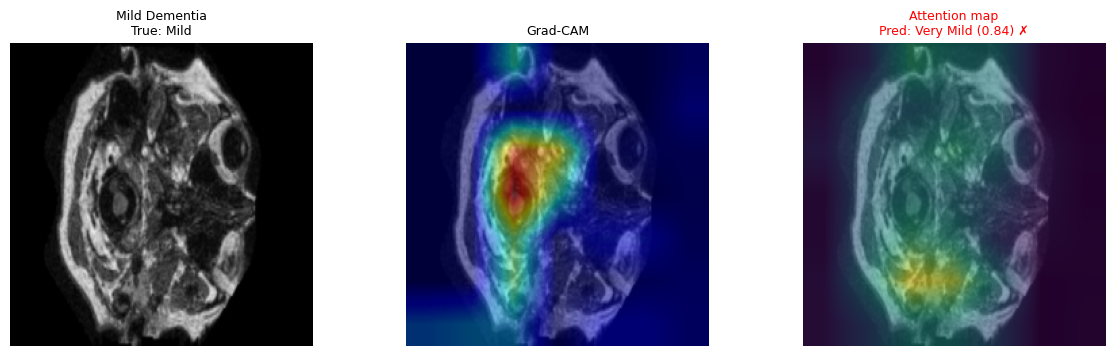

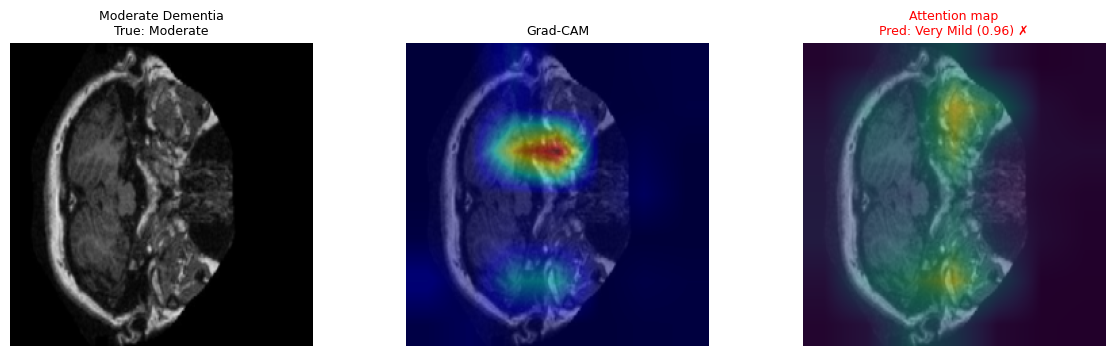

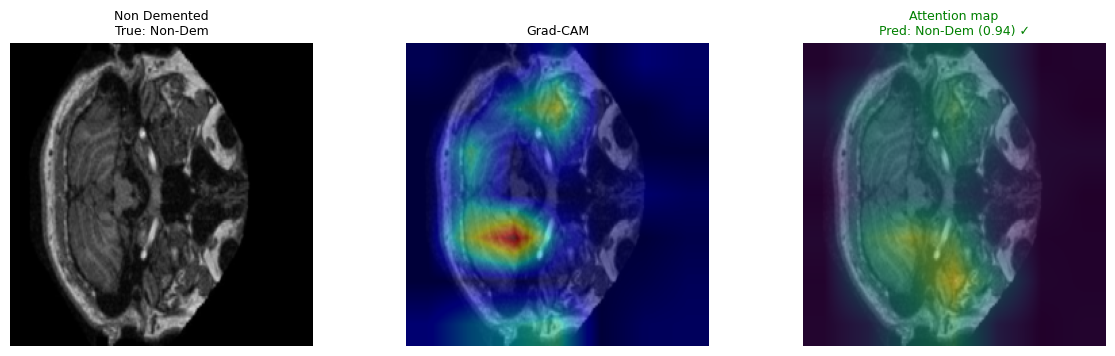

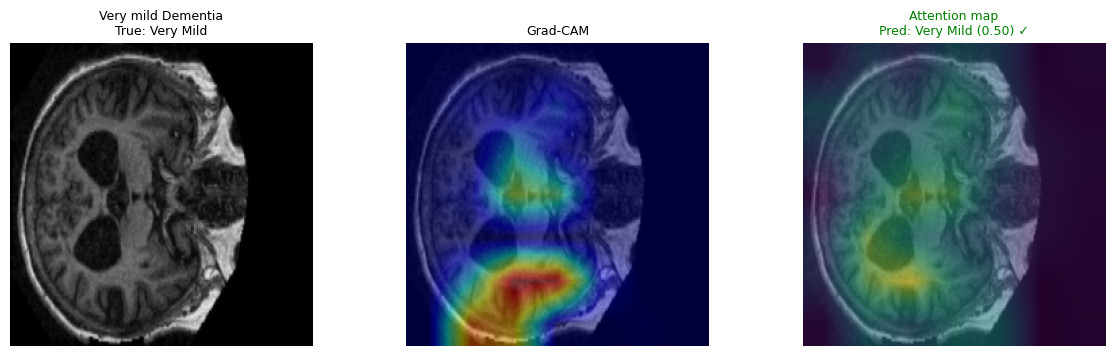

In [18]:
model.eval()
for cls_idx in range(n_classes):
    row = val_df[val_df.label == cls_idx].iloc[0]
    img = Image.open(row.path).convert("L")
    img_tensor = val_transform(img)
    show_sample(model, img_tensor, cls_idx, title_prefix=class_names_folder[cls_idx])

## 15 · Predictions

In [19]:
model.eval()
records = []
for batch in val_loader:
    imgs = batch["pixel_values"].to(device)
    labels = batch["labels"]
    paths = batch["path"]
    with torch.no_grad():
        logits = model(imgs)
        probs = F.softmax(logits, dim=1)
        preds = logits.argmax(-1)
        confs = probs.max(dim=1).values
    for p, tl, pl, cf in zip(paths, labels.numpy(), preds.cpu().numpy(), confs.cpu().numpy()):
        records.append((p, int(tl), int(pl), float(cf)))
correct   = [(p,t,pr,c) for p,t,pr,c in records if t == pr]
incorrect = [(p,t,pr,c) for p,t,pr,c in records if t != pr]


── Two CORRECT predictions ──


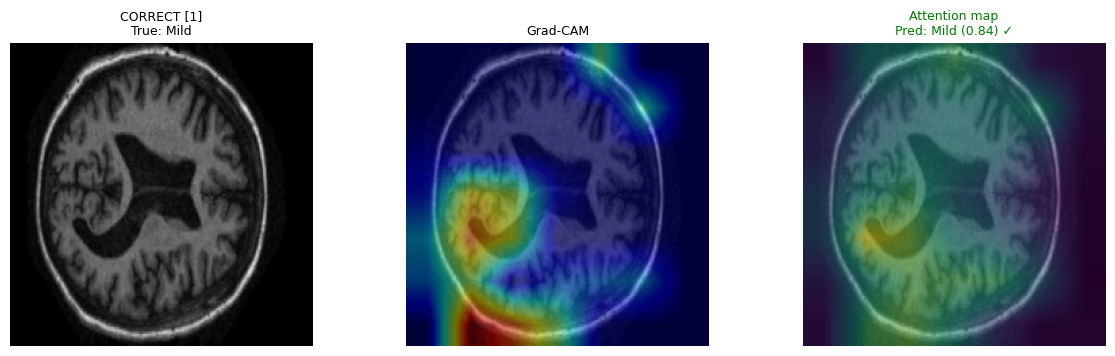

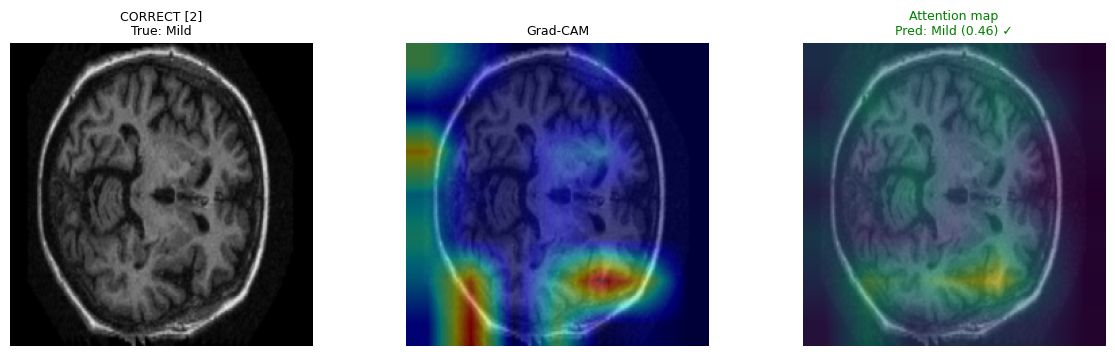


── Two INCORRECT predictions ──


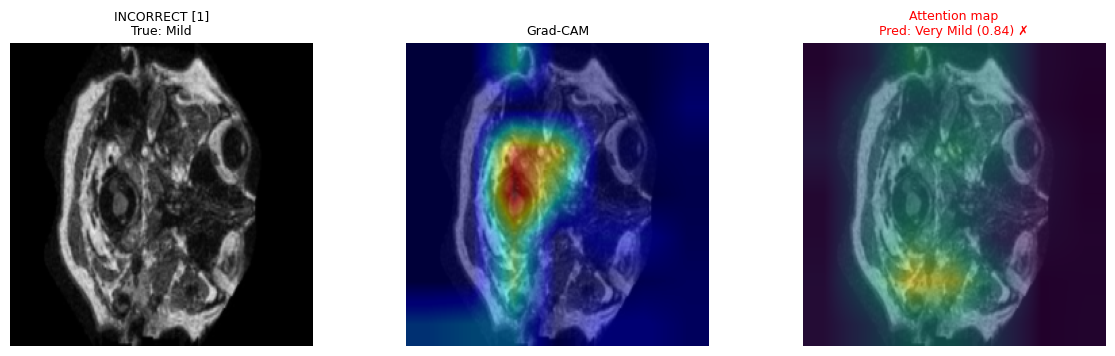

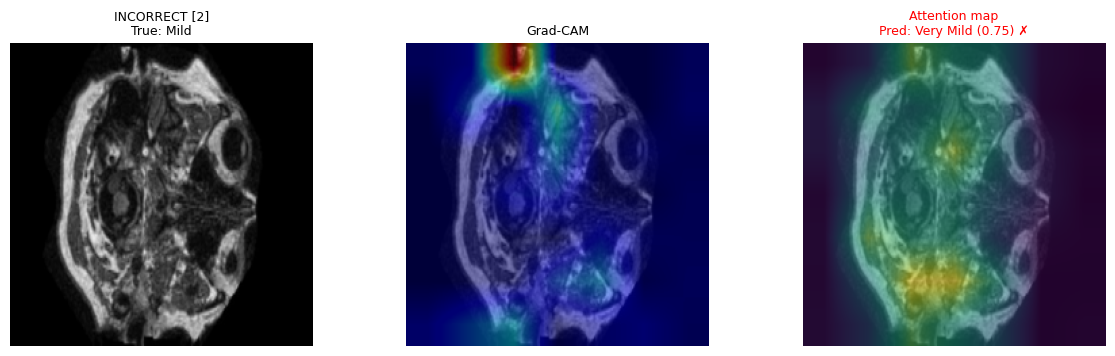

In [20]:
def show_from_record(model, record, title_prefix):
    path, true_label, pred_label, conf = record
    img = Image.open(path).convert("L")
    img_tensor = val_transform(img)
    show_sample(model, img_tensor, true_label, title_prefix=title_prefix)

print("\n── Two CORRECT predictions ──")
for i, rec in enumerate(correct[:2]):
    show_from_record(model, rec, f"CORRECT [{i+1}]")
print("\n── Two INCORRECT predictions ──")
for i, rec in enumerate(incorrect[:2]):
    show_from_record(model, rec, f"INCORRECT [{i+1}]")